# Tarea 4. El banco portugués que no sabía llamar:(

Lucy Torres Durante
---

1. Antes de modelar, leemos `bank-additional-names.txt`. ¿Cuál de las variables podría no conocerse antes de hacer una llamada?

```11 - duration: last contact duration, in seconds (numeric). Important note:  this attribute highly affects the output target (e.g., if duration=0 then y="no"). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
```

No se puede saber la duración de la llamada sin antes llamarla, por lo que esta es la variable que voy a quitar (además es la que más impacto tiene).

In [2]:
import os
from pathlib import Path

print(os.getcwd())        # '/Users/you/projects'
print(Path.cwd())         # '/Users/you/projects'

/Users/luis/Documents/Cicese/Masters/cienciadedatos/tareas/Tarea4
/Users/luis/Documents/Cicese/Masters/cienciadedatos/tareas/Tarea4


In [3]:

import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('./bank-additional-full.csv', sep=';')

display(f"Shape: {df.shape}")
display(df.head())
display(df.info())
display(df.describe())
display(df.head(5)) 


'Shape: (41188, 21)'

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

None

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
display("numero de personas que contrataron el credito:",df['y'].value_counts())
display("Porcentaje de personas que contrataron el credito", df['y'].value_counts(normalize=True)
)

'numero de personas que contrataron el credito:'

y
no     36548
yes     4640
Name: count, dtype: int64

'Porcentaje de personas que contrataron el credito'

y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64

¡Aquí hay una desproporción enorme entre las personas que aceptan y las que no! Hay que tenerlo en cuenta a la hora de entrenar el modelo.

Vamos a ver cuántos missing values hay.

In [5]:
report = (
    df.astype(str)
      .apply(lambda s: s.str.strip().str.lower().eq("unknown").sum())
      .sort_values(ascending=False)
)
print(report[report > 0])

default      8597
education    1731
housing       990
loan          990
job           330
marital        80
dtype: int64


In [6]:
cat_cols = df.select_dtypes(include="object").columns.drop("y")

for c in cat_cols:
    vals = sorted(df[c].astype(str).str.strip().str.lower().unique())
    print(f"\n{c} ({len(vals)} categories):")
    print(vals)


job (12 categories):
['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']

marital (4 categories):
['divorced', 'married', 'single', 'unknown']

education (8 categories):
['basic.4y', 'basic.6y', 'basic.9y', 'high.school', 'illiterate', 'professional.course', 'university.degree', 'unknown']

default (3 categories):
['no', 'unknown', 'yes']

housing (3 categories):
['no', 'unknown', 'yes']

loan (3 categories):
['no', 'unknown', 'yes']

contact (2 categories):
['cellular', 'telephone']

month (10 categories):
['apr', 'aug', 'dec', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']

day_of_week (5 categories):
['fri', 'mon', 'thu', 'tue', 'wed']

poutcome (3 categories):
['failure', 'nonexistent', 'success']


/var/folders/bg/cpfr08ss4blg9k1_jk8bvf480000gn/T/ipykernel_23532/3482949761.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.drop("y")


Pensé en quitar los duplicados, pero para este caso no hay identificadores ni alguna variable que diga que las personas son distintas entre sí. Al ser solo 12, no es necesario quitarlos, y es plausible que haya 12 duplicados reales; aun así, como son tan poquitos, los voy a quitar.

In [7]:
df.duplicated().sum()

np.int64(12)

In [8]:
df = df.drop_duplicates()

Siguiendo con el EDA.

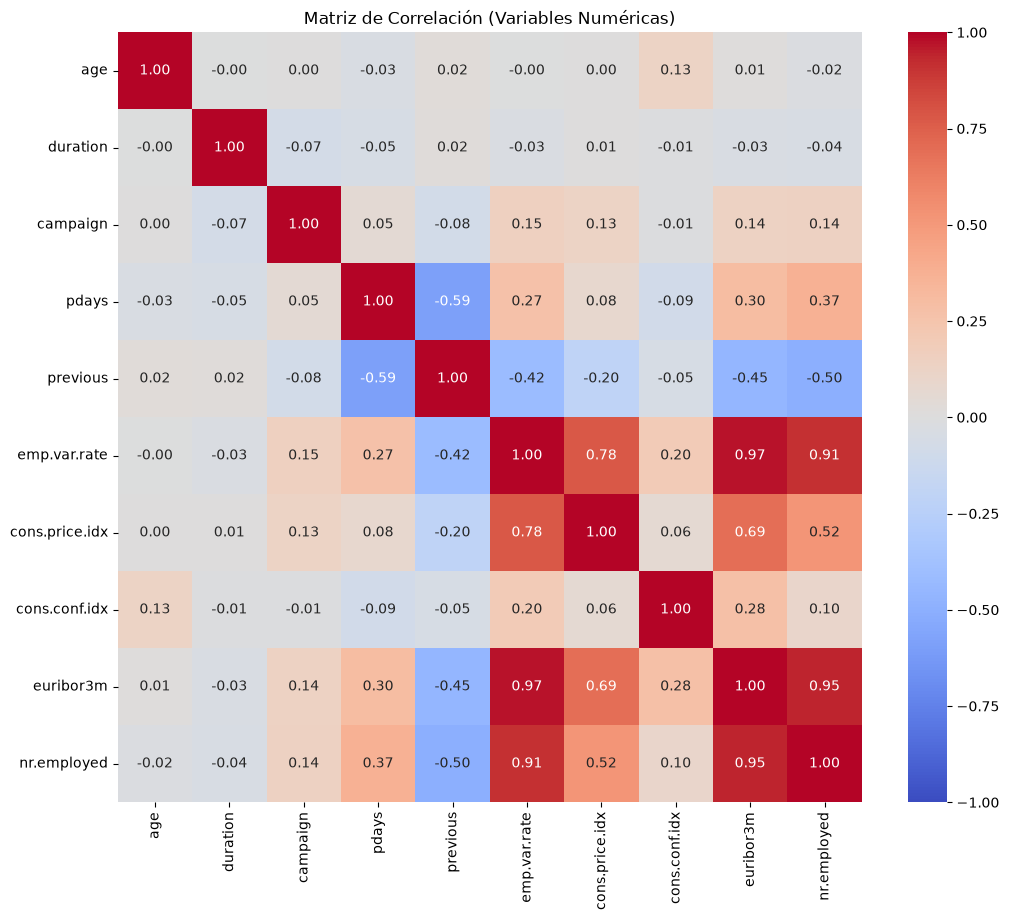

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Seleccionamos solo columnas númericas.
df_numerico = df.select_dtypes(include=['int64', 'float64'])

# 2. Calcular la matriz de correlación
matriz_corr = df_numerico.corr()

plt.figure(figsize=(12, 10))

# 4. Dibujar el Heatmap
sns.heatmap(
    matriz_corr, 
    annot=True,      # Pone los números dentro de los cuadros
    fmt=".2f",       # Redondea a 2 decimales
    cmap="coolwarm", # Colores: azul (positivo), rojo (negativo)
    vmin=-1, vmax=1, # Escala de -1 a 1
    center=0         # El color blanco será el 0
)

plt.title('Matriz de Correlación (Variables Numéricas)')
plt.show()

Hacemos one-hot encoding (TEMPORAL) para poder visualizar las variables con texto: a cada categoría se le asigna un entero y la relacionamos con `y`.

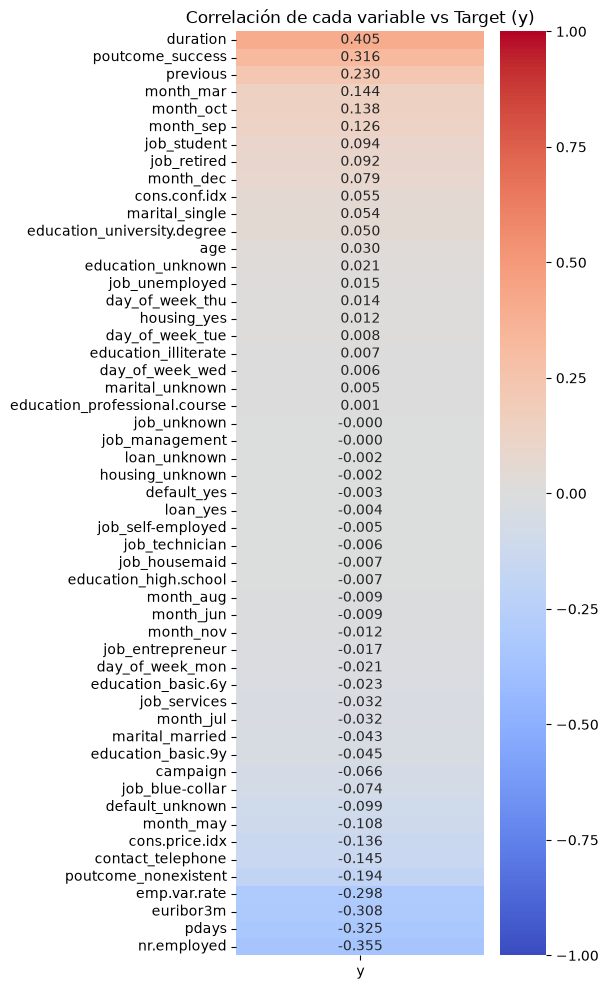

In [10]:
# 1. Creas la COPIA solo para explorar
df_explorar = df.copy()

# 2. MAPEAMOS la variable y (Opción B: 'no' -> 0, 'yes' -> 1)
df_explorar['y'] = df_explorar['y'].map({'no': 0, 'yes': 1})

# 3. Haces el OHE en la copia (Pandas ignorará 'y' porque ahora es numérica)
df_explorar = pd.get_dummies(df_explorar, drop_first=True)

# 4. Calculas la matriz de correlación completa
matriz = df_explorar.corr()

# Filtramos la matriz para que SOLO muestre la columna 'y' (y quitar la fila 'y' que es 1.0)
matriz_y = matriz[['y']].drop(index='y').sort_values(by='y', ascending=False)

# Hacemos el heatmap de esta columna única (se verá como una tira vertical)
plt.figure(figsize=(4, 12)) # Alto y delgado
sns.heatmap(matriz_y, cmap='coolwarm', center=0, vmin=-1, vmax=1, annot=True, fmt=".3f")
plt.title('Correlación de cada variable vs Target (y)')
plt.show()

Tiene sentido lo que estamos viendo. `duration` es la que tiene mayor relación, porque solo sabemos cuánto duró al final de la llamada, y es súper probable que, si duraron tiempo en la llamada, hayan aceptado.

Variables que hacen que acepten:
1. `poutcome_success`: si aceptaron en el pasado, es probable que acepten de nuevo.
2. `previous`: las personas que han sido contactadas más veces tienen una mayor probabilidad de aceptar.

df.columns

## ¿Feature engineering?

Ahora sí podemos eliminar `duration` para trabajar con el modelo.

In [11]:

df = df.drop(['duration'], axis=1) #Eliminamos la columna duration
print(df.columns) 

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous',
       'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
       'euribor3m', 'nr.employed', 'y'],
      dtype='str')


**Feature engineering de `pdays`.** La columna dice cuántos días pasaron desde el último contacto de una campaña anterior, y pone 999 cuando el cliente nunca fue contactado. Eso es malo para el modelo, porque puede inferir que pasaron 999 días desde la última llamada, lo cual no es cierto. Entonces convertimos `pdays` en dos variables:

- `fue_contactado_antes`: con valores 1 y 0 (sí y no).
- `dias_desde_ultimo_contacto`: el número entero de días desde el último contacto, para los que sí fueron contactados.

In [12]:
df.loc[df['previous'] == 0, 'pdays'] = 999
df['fue_contactado_antes'] = (df['pdays'] != 999).astype(int)
df['dias_desde_ultimo_contacto'] = df['pdays'].replace(999, 0)
df = df.drop(columns=['pdays'])

## 2. Partición de prueba (20 %) y el clasificador que siempre dice «no»

Vamos a generar el modelo de regresión logística, pero primero dividimos el dataset 80/20.

In [13]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['y'])
y = df['y'].map({'no': 0, 'yes': 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

print(f"train {X_train.shape} | test {X_test.shape}")
print(f"prevalencia train {y_train.mean():.4f} | test {y_test.mean():.4f}")
print(f"exactitud de 'siempre no' en prueba: {(y_test == 0).mean():.4f}")

train (32940, 20) | test (8236, 20)
prevalencia train 0.1127 | test 0.1127
exactitud de 'siempre no' en prueba: 0.8873


**Respuesta.** Un clasificador que siempre responde «no» acierta 88.73 % en prueba, que es exactamente la proporción de «no» del conjunto. La exactitud, entonces, es una métrica engañosa en este problema: se puede tener casi 89 % de acierto sin detectar a un solo cliente que compre, que es justo lo que el banco necesita. Por eso el resto del análisis reporta matriz de confusión, precisión, sensibilidad, especificidad y F1.

## 3. Regresión logística dentro de un `Pipeline`

Hacemos la regresión logística con las variables categóricas en one-hot y el escalado dentro de un `Pipeline`: el `ColumnTransformer` manda las categóricas al `OneHotEncoder` y las numéricas al `StandardScaler`, de modo que todo el preprocesamiento se ajuste solo con el conjunto de entrenamiento. Dejamos `unknown` como una categoría más, porque en este dataset no es un dato perdido al azar, sino información (gente que no quiso o no pudo responder). La partición de arriba ya es estratificada, para mantener la proporción de `yes`/`no` en train y en prueba.

In [14]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score)

cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan',
            'contact', 'month', 'day_of_week', 'poutcome']
num_cols = ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx',
            'cons.conf.idx', 'euribor3m', 'nr.employed',
            'fue_contactado_antes', 'dias_desde_ultimo_contacto']

def hacer_pipeline(numericas):
    preprocesador = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols),
        ('num', StandardScaler(), numericas)])
    return Pipeline([('prep', preprocesador),
                     ('clf', LogisticRegression(max_iter=5000, random_state=42))])

def evaluar(nombre, y_true, y_prob, umbral=0.5):
    y_pred = (y_prob >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    sens = recall_score(y_true, y_pred)
    esp  = tn / (tn + fp)
    f1   = f1_score(y_true, y_pred)
    print(f"--- {nombre} | umbral={umbral} ---")
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(f"exactitud {acc:.4f} | precision {prec:.4f} | sensibilidad {sens:.4f}"
          f" | especificidad {esp:.4f} | F1 {f1:.4f}")
    return dict(tn=tn, fp=fp, fn=fn, tp=tp, acc=acc, prec=prec, sens=sens, esp=esp, f1=f1)

modelo = hacer_pipeline(num_cols)
modelo.fit(X_train, y_train)
y_prob = modelo.predict_proba(X_test)[:, 1]
res = evaluar('regresión logística sin duration', y_test, y_prob, 0.5)

--- regresión logística sin duration | umbral=0.5 ---
TN=7203  FP=105  FN=731  TP=197
exactitud 0.8985 | precision 0.6523 | sensibilidad 0.2123 | especificidad 0.9856 | F1 0.3203


**Respuesta.** Con el umbral de 0.5 la matriz de confusión en prueba queda TN = 7,203, FP = 105, FN = 731 y TP = 197: el modelo detecta 197 de los 928 compradores. De ahí salen exactitud 0.8985, precisión 0.6523, sensibilidad 0.2123, especificidad 0.9856 y F1 0.3203, así que la exactitud apenas supera el 0.8873 de no hacer nada y la especificidad altísima esconde que se escapa el 79 % de los que sí compran.

Al banco le importa más la **sensibilidad**: un falso positivo cuesta 5 (una llamada), pero un falso negativo cuesta 50 (un cliente que habría aceptado y no se llamó), y esa asimetría 10:1 es justo la que hace que F1, que pesa igual ambos errores, no sea la métrica adecuada.

## 4. Curvas ROC y precisión–sensibilidad

Generamos la gráfica de ROC y, junto a ella, la de precisión contra sensibilidad, cada una con su AUC y su precisión promedio.

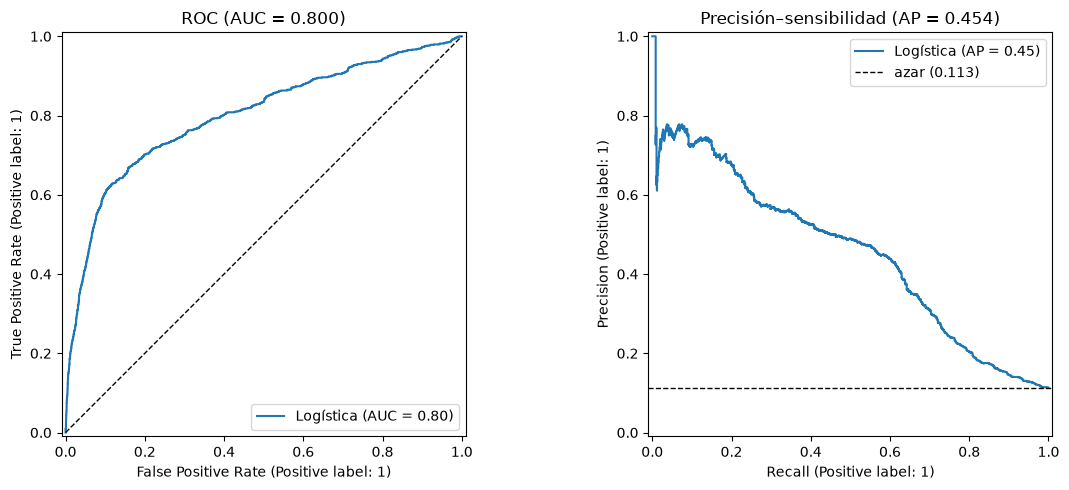

AUC = 0.8003 | precisión promedio = 0.4535 | prevalencia = 0.1127


In [15]:
from sklearn.metrics import (RocCurveDisplay, PrecisionRecallDisplay,
                             roc_auc_score, average_precision_score)
import matplotlib.pyplot as plt

auc = roc_auc_score(y_test, y_prob)
ap  = average_precision_score(y_test, y_prob)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax[0], name='Logística')
ax[0].set_title(f'ROC (AUC = {auc:.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', lw=1)

PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=ax[1], name='Logística')
ax[1].axhline(y_test.mean(), color='k', ls='--', lw=1,
              label=f'azar ({y_test.mean():.3f})')
ax[1].set_title(f'Precisión–sensibilidad (AP = {ap:.3f})')
ax[1].legend()
plt.tight_layout(); plt.show()

print(f"AUC = {auc:.4f} | precisión promedio = {ap:.4f} | prevalencia = {y_test.mean():.4f}")

**Respuesta.** La ROC da un AUC de 0.800 y la curva de precisión–sensibilidad una precisión promedio de 0.454, frente a 0.113 que sería el azar (la prevalencia). La ROC se ve sana porque su tasa de falsos positivos se calcula sobre los 7,308 «no», que son la gran mayoría, y eso diluye el daño de equivocarse en los pocos positivos. La curva de precisión–sensibilidad lo expone: para llegar a una sensibilidad de 0.68 la precisión cae a 0.33, es decir, tres de cada cuatro llamadas serían en falso, que es lo que la primera curva esconde cuando los positivos son pocos.

## 5. Umbral económico

Ya tenemos el modelo; ahora hay que decidir a partir de qué probabilidad conviene llamar.

In [16]:
def ganancia(y_true, y_pred, costo_llamada=5, ingreso=50):
    y_true = np.asarray(y_true)
    return int(((ingreso * y_true - costo_llamada) * np.asarray(y_pred)).sum())

p_opt = 5 / 50   # punto de equilibrio
print(f"umbral de conveniencia: p > {p_opt}")

for u in [0.5, p_opt]:
    y_pred = (y_prob >= u).astype(int)
    print(f"umbral {u:.2f}: {y_pred.sum():>4} llamadas | "
          f"TP={((y_pred==1)&(y_test.values==1)).sum():>4} | "
          f"ganancia = {ganancia(y_test, y_pred):>7}")

umbral de conveniencia: p > 0.1
umbral 0.50:  302 llamadas | TP= 197 | ganancia =    8340
umbral 0.10: 1932 llamadas | TP= 632 | ganancia =   21940


**Respuesta.** Como cada llamada cuesta 5 y cada aceptación deja 50, llamar conviene cuando 50·p − 5 > 0, o sea con **p > 0.10**. Con el umbral 0.5 se hacen 302 llamadas y se logran 8,340 de ganancia en prueba, mientras que con 0.10 se hacen 1,932 llamadas y la ganancia sube a 21,940, 2.6 veces más. El óptimo empírico de la rejilla cae en 0.109 con 22,095, prácticamente el mismo 0.10 que da la cuenta, y así el umbral de 0.5 deja sobre la mesa unos 13,600 de ganancia potencial.

## 6. Repetimos el punto 3 incluyendo `duration`

Releemos el dataset para comparar de nuevo, ahora con `duration` dentro del modelo.

In [17]:
import pandas as pd

df_full = pd.read_csv('./bank-additional-full.csv', sep=';')
df_full = df_full.drop_duplicates().reset_index(drop=True)
df_full.loc[df_full['previous'] == 0, 'pdays'] = 999
df_full['fue_contactado_antes'] = (df_full['pdays'] != 999).astype(int)
df_full['dias_desde_ultimo_contacto'] = df_full['pdays'].replace(999, 0)
df_full = df_full.drop(columns=['pdays'])
# se conserva duration

X2 = df_full.drop(columns=['y'])
y2 = df_full['y'].map({'no': 0, 'yes': 1})
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.20, stratify=y2, random_state=42)   # misma semilla = mismas filas

modelo2 = hacer_pipeline(num_cols + ['duration'])
modelo2.fit(X2_train, y2_train)
y2_prob = modelo2.predict_proba(X2_test)[:, 1]

res2 = evaluar('regresión logística CON duration', y2_test, y2_prob, 0.5)
print(f"AUC {roc_auc_score(y2_test, y2_prob):.4f} | "
      f"AP {average_precision_score(y2_test, y2_prob):.4f} | "
      f"ganancia@0.5 {ganancia(y2_test, (y2_prob>=0.5).astype(int))}")

--- regresión logística CON duration | umbral=0.5 ---
TN=7093  FP=215  FN=534  TP=394
exactitud 0.9091 | precision 0.6470 | sensibilidad 0.4246 | especificidad 0.9706 | F1 0.5127
AUC 0.9389 | AP 0.6007 | ganancia@0.5 16655


**Respuesta.** Al volver a incluir `duration` la matriz de confusión queda TN = 7,093, FP = 215, FN = 534 y TP = 394, y todas las métricas suben: exactitud 0.9091, precisión 0.6470, sensibilidad 0.4246, especificidad 0.9706, F1 0.5127, AUC 0.9389 y precisión promedio 0.6007 (la ganancia con 0.5 pasa de 8,340 a 16,655).

No le sirve al banco: la duración solo se conoce después de colgar, así que no se puede usar para decidir a quién llamar, y la mejora es pura fuga de información (la duración media es 221 s cuando dicen «no» y 553 s cuando dicen «sí»). Es útil como diagnóstico de qué pasa en la llamada, no como modelo de contacto.

#### **Nota sobre el uso de IA.** Se utilizó DeepSeek para asistencia en el código y para la reestructuración del texto.